# CS781 Phase 3 — Rhetorical Roles — Arch 4: Efficient Transformer (sliding-window attention + GQA) (`ARCH = "mistral_swa"`)
Adapts **your Phase-1 checkpoint** `P1_REPOS[ARCH]` (`best/`; bart = the v2 retrain) to sentence-level rhetorical-role
prediction on Corporate Law (CL) and IT documents: exactly one of the 13 official labels per sentence.

| | |
|---|---|
| Backbone | Phase-1 `MistralForCausalLM` body (`MistralModel`), causal sliding-window attention by default (`ATTN`) |
| Sentence vector | token states of the sentence pooled by `POOL` (`mean` / `first` / `last`) |
| Context (`CONTEXT`) | `none`: every sentence is encoded on its own; `window`: consecutive sentences share one sequence (`WIN_TOKENS`), so tokens see neighbouring sentences (both sides only with bidirectional attention) |
| Sentence-level context | optional BiLSTM over the sentence vectors of a window (`SENT_LSTM`) |
| Head (`HEAD`) | `linear` (per-sentence softmax) or `crf` (linear-chain CRF over the sentence sequence of a document) |
| Long documents | overlapping sentence windows; a sentence's scores are averaged over every window that contains it |
| Methods (`METHOD`) | `lora`, `rslora`, `lorma` (LoRMA), `ia3`, `prompt` (prompt tuning), `kd` (distillation), `full` (reference only) |
| Outputs | `submission_<RUN_NAME>.zip` + run files (scores, dev/test predictions, train-set scores for distillation) in private repo `<hf-user>/cs781-p3` under `runs/<RUN_NAME>/` |

**Before you start**
1. Runtime -> Change runtime type -> **T4 GPU**.
2. Secrets (key icon) -> `HF` = the **same** HF token as Phases 1–2 (reads your `cs781-p1-*` repos and the gated course
   dataset, writes `cs781-p3`).
3. Choose `METHOD`, `CONTEXT`, `HEAD`, `SENT_LSTM` in the first code cell, check *Configuration*, then **Run all**.

Another experiment on the same account: change the first cell (the run name follows), **Run all** again — every run
starts from the Phase-1 checkpoint. `kd` needs a finished teacher run in `cs781-p3` (`TEACHER_RUN`, any architecture:
the student learns from the per-sentence scores the teacher run saved for the training documents).

Phase-3 rules (capstone §1, §9.2): ≥6 submissions; all four Phase-1 models used; ≥4 substantially different
experiments, of which ≥3 use different fine-tuning / PEFT techniques **from the §9.2.1 list** (LoRA, QLoRA, AdaLoRA,
rsLoRA, LoRMA, Prefix Tuning, Prompt Tuning, IA³, KD) with **LoRMA compulsory**, and ≥1 is knowledge distillation;
runs that differ only in hyperparameters do not count. Full fine-tuning is **not** on the §9.2.1 list — it is here
as a reference point for "can PEFT approach full adaptation" (§9.5).

In [1]:
ARCH = "mistral_swa"                 # fixed for this notebook
METHOD = "lorma"                  # "lora" | "rslora" | "lorma" | "ia3" | "prompt" | "kd" | "full" (reference)
CONTEXT = "window"                # "none" (each sentence alone) | "window" (consecutive sentences in one sequence)
HEAD = "linear"                   # "linear" | "crf"
SENT_LSTM = 0                     # 0 = off, else hidden size of a BiLSTM over the sentence vectors (before the head)
RUN_NAME = (f"{ARCH}_{METHOD}_{CONTEXT}" + ("_crf" if HEAD == "crf" else "")
            + (f"_lstm{SENT_LSTM}" if SENT_LSTM else ""))       # unique per experiment

In [2]:
import os, json, math, time, random, zipfile, gc
from collections import Counter
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from huggingface_hub import login, whoami, HfApi, hf_hub_download, snapshot_download
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix

def get_hf_token():
    try:
        from google.colab import userdata
        return userdata.get("HF")
    except Exception:
        pass
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF")
    except Exception:
        return os.environ["HF_TOKEN"]

HF_TOKEN = get_hf_token()
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)
HF_USER = whoami(token=HF_TOKEN)["name"]
api = HfApi(token=HF_TOKEN)

def hub_push(fn, what, tries=3):
    for t in range(1, tries + 1):
        try:
            fn(); return True
        except Exception as e:
            print(f"  !! {what} upload failed ({t}/{tries}): {e!r}")
            time.sleep(30 * t)
    return False

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
assert DEVICE == "cuda" or os.environ.get("CS781_ALLOW_CPU"), "Switch the runtime to a GPU"
AMP = DEVICE == "cuda"
print(torch.__version__, torch.cuda.get_device_name(0) if AMP else "CPU")
import transformers; print("transformers", transformers.__version__)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


2.11.0+cu130 Tesla T4
transformers 5.18.0


## Configuration — **all values below are YOUR CHOICE** (document them in the report)

In [3]:
DATASET = "Exploration-Lab/CS-781-Capstone"
# Phase-1 checkpoint (best/) per architecture; bart = the v2 retrain (v1 `cs781-p1-bart` collapsed, never use it)
P1_REPOS = {"llama": f"{HF_USER}/cs781-p1-llama", "bart": f"{HF_USER}/cs781-p1-bart-v2",
            "prefixlm": f"{HF_USER}/cs781-p1-prefixlm", "mistral_swa": f"{HF_USER}/cs781-p1-mistral_swa"}
P3_REPO = f"{HF_USER}/cs781-p3"             # all Phase-3 runs: runs/<RUN_NAME>/...
WORK = "/content/p3" if os.path.isdir("/content") else "/tmp/p3"
RUN_DIR = f"{WORK}/{RUN_NAME}"
os.makedirs(RUN_DIR, exist_ok=True)

SEED = 42
TRAIN_DOMAINS = ["CL", "IT"]   # whose <domain>_train.json documents are trained on; model selection is always on
                               # CL_dev + IT_dev pooled (like the official scorer); test predictions always cover CL + IT

# Sentences and context
MAX_SENT_TOKENS = 128      # a longer sentence keeps its first MAX_SENT_TOKENS tokens
WIN_SENTS = 24             # max sentences per window (CONTEXT "none": sentences per group seen by the LSTM / CRF)
WIN_TOKENS = 512           # CONTEXT "window": token budget of a window (sentences are never split across windows)
STRIDE_TRAIN = 12          # sentences between consecutive window starts, training
STRIDE_PRED = 6            # ... prediction (dev / test); scores of a sentence are averaged over its windows
POOL = "mean"              # token states -> sentence vector: "mean" | "first" | "last"

# How the backbone attends
#   decoder-only models: "causal" (as pretrained) or "bidirectional" (full mask; for mistral_swa a ±window band)
ATTN = {"llama": "causal", "prefixlm": "bidirectional", "mistral_swa": "causal", "bart": "n/a"}[ARCH]
#   bart: "encoder" = encoder states only; "decoder" = input fed to encoder AND decoder, decoder states
BART_MODE = "encoder"

# Optimisation
EPOCHS = 10
PATIENCE = 3               # stop after this many epochs without a dev macro-F1 improvement
MAX_TRAIN_MINUTES = 60     # hard cap on training time; the best epoch so far is kept
BATCH = 8                  # windows per step
LR = {"full": 5e-5, "lora": 5e-4, "rslora": 5e-4, "lorma": 5e-4, "ia3": 3e-3, "prompt": 3e-3, "kd": 1e-4}[METHOD]
HEAD_LR = 1e-3             # head, CRF and LSTM
WEIGHT_DECAY = 0.01
WARMUP_FRAC = 0.06
GRAD_CLIP = 1.0
DROPOUT = 0.1
CLASS_WEIGHTS = "none"     # "none" | "inverse" | "inverse_sqrt": per-label loss weights from training label counts
                           # (linear head; the CRF likelihood is unweighted)

# Method-specific
ADAPT_TARGETS = ["q_proj", "v_proj"]    # lora / rslora / lorma: names of the nn.Linear layers that get adapters
RANK, ALPHA = 8, 16                     # lora scale alpha/r; rslora scale alpha/sqrt(r)
LORMA_VARIANT = "plus"                  # "plus" = additive-identity rank inflation, "pi" = permutation inflation
IA3_OUT = ["k_proj", "v_proj"]          # ia3: outputs rescaled by a learned vector (keys, values)
IA3_IN = ["down_proj", "fc2"]           # ia3: inputs rescaled (FFN activation; llama/mistral down_proj, bart fc2)
PROMPT_LEN = 20                         # prompt: learned soft tokens prepended to every sequence

# Knowledge distillation (METHOD == "kd"); the student is this notebook's ARCH with fewer Phase-1 blocks
TEACHER_RUN = "llama_full_window"       # a finished run in P3_REPO (it saved train_scores.json)
STUDENT_LAYERS = None                   # None = every 2nd block (per stack for bart), or an explicit list
KD_T = 2.0
KD_ALPHA = 0.5                          # loss = KD_ALPHA * task loss + (1 - KD_ALPHA) * T^2 * KL(teacher || student)

SAVE_WEIGHTS = False                    # merged fine-tuned weights to the Hub (not needed for distillation)

assert METHOD in ("lora", "rslora", "lorma", "ia3", "prompt", "kd", "full"), METHOD
assert CONTEXT in ("none", "window") and HEAD in ("linear", "crf") and POOL in ("mean", "first", "last")
assert CLASS_WEIGHTS in ("none", "inverse", "inverse_sqrt") and set(TRAIN_DOMAINS) <= {"CL", "IT"}
assert MAX_SENT_TOKENS <= WIN_TOKENS, "a sentence must fit in a window"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

## Data: download, inspect, parse
The raw first record of each file is printed so the format can be checked by eye. Train / dev documents carry
`text` (ordered sentences) and `labels`; test documents carry sentences only. The label vocabulary is read with the
same rules as `evaluate_phase3.py`.

In [4]:
def fetch(rel):
    return hf_hub_download(DATASET, f"Phase_3_RR/{rel}", repo_type="dataset", token=HF_TOKEN)

def read_json_any(path):
    txt = open(path, encoding="utf-8").read()
    try:
        return json.loads(txt)
    except json.JSONDecodeError:                       # JSON Lines
        return [json.loads(l) for l in txt.splitlines() if l.strip()]

def as_docs(raw):
    """-> {doc_id: (sentences, labels or None)} from a list of {id, text, labels} records, a dict id -> record,
    or a dict id -> list of sentences."""
    items = raw.items() if isinstance(raw, dict) else [(r.get("id", r.get("doc_id")), r) for r in raw]
    out = {}
    for k, v in items:
        if isinstance(v, list):
            sents, labs = v, None
        else:
            sents = v.get("text", v.get("sentences"))
            labs = v.get("labels", v.get("label"))
        assert k is not None and isinstance(sents, list), f"unexpected record: {repr(v)[:200]}"
        assert str(k) not in out, f"duplicate document id {k}"
        out[str(k)] = ([str(s) for s in sents], None if labs is None else [str(l) for l in labs])
    return out

def load_vocab(data):
    if isinstance(data, list):
        return list(data)
    vals = list(data.values())
    if all(isinstance(v, int) and not isinstance(v, bool) for v in vals):
        return sorted(data, key=data.get)          # label -> id
    return vals                                     # id -> label

LABELS = load_vocab(read_json_any(fetch("Train/label_vocab.json")))
assert len(LABELS) == 13 and len(set(LABELS)) == 13, LABELS
lab2id = {l: i for i, l in enumerate(LABELS)}
C = len(LABELS)
print("labels:", LABELS)

FILES = {("CL", "train"): "Train/CL_train.json", ("IT", "train"): "Train/IT_train.json",
         ("CL", "dev"): "Train/CL_dev.json", ("IT", "dev"): "Train/IT_dev.json",
         ("CL", "test"): "Test/CL_test.json", ("IT", "test"): "Test/IT_test.json"}
DOCS = {}                                            # doc_id -> dict(sents, labels, domain, split)
for (dom, split), rel in FILES.items():
    raw = read_json_any(fetch(rel))
    first = raw[next(iter(raw))] if isinstance(raw, dict) else raw[0]
    print(f"{rel}: {type(raw).__name__} of {len(raw)}  first record: {repr(first)[:250]}")
    for d, (sents, labs) in as_docs(raw).items():
        assert d not in DOCS, f"document id {d} appears in two files"
        if split != "test":
            assert labs is not None and len(labs) == len(sents), f"{d}: {len(sents)} sentences vs {len(labs or [])} labels"
            bad = sorted(set(labs) - set(LABELS))
            assert not bad, f"{d}: labels outside label_vocab.json: {bad}"
        DOCS[d] = dict(sents=sents, labels=labs if split != "test" else None, domain=dom, split=split)

TRAIN_IDS = sorted(d for d, r in DOCS.items() if r["split"] == "train" and r["domain"] in TRAIN_DOMAINS)
DEV_IDS = sorted(d for d, r in DOCS.items() if r["split"] == "dev")
TEST_IDS = sorted(d for d, r in DOCS.items() if r["split"] == "test")
Y = {d: [lab2id[l] for l in r["labels"]] for d, r in DOCS.items() if r["labels"] is not None}

print(f"\n{'domain':6s} {'split':5s} {'docs':>5s} {'sentences':>9s} {'empty':>6s} {'sent/doc med':>12s}")
for (dom, split) in FILES:
    ds = [r for r in DOCS.values() if r["domain"] == dom and r["split"] == split]
    ns = [len(r["sents"]) for r in ds]
    print(f"{dom:6s} {split:5s} {len(ds):5d} {sum(ns):9d} {sum(1 for r in ds for s in r['sents'] if not s.strip()):6d} "
          f"{int(np.median(ns)) if ns else 0:12d}")
print(f"training on {TRAIN_DOMAINS}: {len(TRAIN_IDS)} docs; dev {len(DEV_IDS)} docs; test {len(TEST_IDS)} docs")

print(f"\nsentences per label (counts):\n{'label':24s}" + "".join(f"{f'{d} {s}':>10s}" for d in ("CL", "IT") for s in ("train", "dev")))
cnts = {(dm, sp): Counter(l for r in DOCS.values() if r["domain"] == dm and r["split"] == sp for l in r["labels"])
        for dm in ("CL", "IT") for sp in ("train", "dev")}
for l in LABELS:
    print(f"{l:24s}" + "".join(f"{cnts[(dm, sp)][l]:10d}" for dm in ("CL", "IT") for sp in ("train", "dev")))

label_vocab.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

labels: ['Fact', 'Issue', 'ArgumentPetitioner', 'ArgumentRespondent', 'Statute', 'Dissent', 'PrecedentReliedUpon', 'PrecedentNotReliedUpon', 'PrecedentOverruled', 'RulingByLowerCourt', 'RatioOfTheDecision', 'RulingByPresentCourt', 'None']


CL_train.json:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

Train/CL_train.json: list of 40  first record: {'id': 'CCI_All_India_Distillers_Association_vs_Haldyn_Glass_GCO100028COM855733', 'text': ['Consequent upon the repeal of the MRTP Act this complaint has been received by transfer on 04.03.2010 from the office of DGIR, MRTP Commission under Section 6


IT_train.json:   0%|          | 0.00/1.51M [00:00<?, ?B/s]

Train/IT_train.json: list of 40  first record: {'id': 'BHC_BomHC_1981_215', 'text': ['Sujata Manohar, J. The assessees in Income-tax Reference Number 98 of 1971 and Income-tax Reference Number 194 of 1975 are partners in the firm of M section K, C. Shah and Company.', 'Apart from these two asses-


... (4 outputs left out)

CL_test.json:   0%|          | 0.00/281k [00:00<?, ?B/s]

Test/CL_test.json: dict of 5  first record: ['Manmohan, J. 1 .', 'Present writ petition has been filed, challenging the notice dated 26th February, 2016 and respondent Number 1s order dated 18th February, 2016 whereby the respondent-CCI has directed the opposite parties in Reference Case Numbe


IT_test.json:   0%|          | 0.00/194k [00:00<?, ?B/s]

Test/IT_test.json: dict of 5  first record: ['B. Sinha, J. Leave granted.', 'These two appeals, being interconnected, were taken up for hearing together and are being disposed of by this common judgment.', 'They arise out of a common judgment and order dated 2.3.2006 in ITA Number 50 of 2005 a

domain split  docs sentences  empty sent/doc med
CL     train    40     10593      0          120
IT     train    40      6252      0          126
CL     dev       5      1396      0          184
IT     dev       5       746      0          120
CL     test      5      1339      0          114
IT     test      5       858      0          159
training on ['CL', 'IT']: 80 docs; dev 10 docs; test 10 docs

sentences per label (counts):
label                     CL train    CL dev  IT train    IT dev
Fact                          2979       249      1119       195
Issue                           17         3        90        12
ArgumentPetitioner             976       344       637        56
ArgumentR

## Tokenizer and sentence tokens
Each sentence is tokenised as `" " + sentence` (byte-level BPE: inside running text a sentence follows a space), then
truncated to `MAX_SENT_TOKENS`. An empty sentence becomes a single `<|endoftext|>` token so it still gets a vector.

In [5]:
from transformers import PreTrainedTokenizerFast

P1_DIRS = {}
def p1_dir(arch):
    if arch not in P1_DIRS:
        try:
            path = snapshot_download(P1_REPOS[arch], token=HF_TOKEN, allow_patterns=["best/*"])
        except Exception as e:
            raise RuntimeError(f"cannot read {P1_REPOS[arch]}/best -- has its Phase-1 notebook finished? ({e!r})")
        P1_DIRS[arch] = os.path.join(path, "best")
    return P1_DIRS[arch]

tokenizer = PreTrainedTokenizerFast.from_pretrained(p1_dir(ARCH))
tokenizer.model_max_length = 10**9
PAD_ID, EOS_ID, VOCAB = tokenizer.pad_token_id, tokenizer.eos_token_id, len(tokenizer)

t0 = time.time()
TOKS, raw_lens = {}, []
for d, r in DOCS.items():
    enc = tokenizer([" " + s.strip() for s in r["sents"]], add_special_tokens=False)["input_ids"] if r["sents"] else []
    raw_lens += [len(x) for x in enc]
    TOKS[d] = [x[:MAX_SENT_TOKENS] or [EOS_ID] for x in enc]
raw_lens = np.array(raw_lens)
print(f"tokenised {len(raw_lens)} sentences in {time.time()-t0:.0f}s; tokens/sentence: median {int(np.median(raw_lens))}  "
      f"p90 {int(np.percentile(raw_lens, 90))}  p99 {int(np.percentile(raw_lens, 99))}  max {raw_lens.max()};  "
      f"truncated at {MAX_SENT_TOKENS}: {(raw_lens > MAX_SENT_TOKENS).mean():.2%}")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

tokenised 21184 sentences in 2s; tokens/sentence: median 33  p90 73  p99 169  max 1186;  truncated at 128: 1.90%


## Sentence windows and batches
A window is a run of consecutive sentences `[a, b)` of one document. With `CONTEXT = "window"` its sentences are
concatenated into one sequence of at most `WIN_TOKENS` tokens; with `CONTEXT = "none"` every sentence is its own
sequence and the window only groups sentences for the LSTM / CRF. Consecutive windows start `STRIDE_*` sentences apart.

**Checks**: every sentence is covered by ≥1 window; pooling + regrouping returns each sentence's own tokens in the
right order (verified by pooling the token ids themselves); the labels of a window are the document's labels.

In [6]:
TEACHER = None    # filled by the distillation cell: doc -> (n_sentences, C) teacher scores

def sent_windows(d, stride):
    lens = [len(t) for t in TOKS[d]]; n = len(lens); out, a = [], 0
    while a < n:
        b, tot = a, 0
        while b < n and b - a < WIN_SENTS and (CONTEXT == "none" or b == a or tot + lens[b] <= WIN_TOKENS):
            tot += lens[b]; b += 1
        out.append((a, b))
        if b == n:
            break
        a += max(1, min(stride, b - a))
    return out

def collate(jobs):
    """jobs: list of (doc, a, b) -> dict of tensors
    ids / att (Q, L): Q sequences (one per window, or one per sentence when CONTEXT == "none")
    pool (Q, K, L): token weights of the K sentences of each sequence
    take (B, S): row of each window sentence in the flattened (Q*K) sentence vectors, -1 = padding
    y (B, S): label ids, -100 = padding / unlabelled;  tsc / tmask: teacher scores (distillation only)"""
    seqs, spans, rows = [], [], []
    for d, a, b in jobs:
        if CONTEXT == "window":
            ids, sp = [], []
            for t in TOKS[d][a:b]:
                sp.append((len(ids), len(ids) + len(t))); ids += t
            rows.append([(len(seqs), k) for k in range(len(sp))]); seqs.append(ids); spans.append(sp)
        else:
            rows.append([(len(seqs) + k, 0) for k in range(b - a)])
            for t in TOKS[d][a:b]:
                seqs.append(t); spans.append([(0, len(t))])
    Q, L, K = len(seqs), max(map(len, seqs)), max(map(len, spans))
    ids = torch.full((Q, L), PAD_ID, dtype=torch.long); att = torch.zeros((Q, L), dtype=torch.long)
    pool = torch.zeros((Q, K, L))
    for q, (s, sp) in enumerate(zip(seqs, spans)):
        ids[q, :len(s)] = torch.tensor(s); att[q, :len(s)] = 1
        for k, (u, v) in enumerate(sp):
            if POOL == "mean": pool[q, k, u:v] = 1.0 / (v - u)
            elif POOL == "first": pool[q, k, u] = 1.0
            else: pool[q, k, v - 1] = 1.0
    B, S = len(jobs), max(map(len, rows))
    take = torch.full((B, S), -1, dtype=torch.long); y = torch.full((B, S), -100, dtype=torch.long)
    out = dict(ids=ids, att=att, pool=pool, take=take, y=y)
    if TEACHER is not None:
        out["tsc"] = torch.zeros((B, S, C)); out["tmask"] = torch.zeros((B, S), dtype=torch.bool)
    for i, ((d, a, b), row) in enumerate(zip(jobs, rows)):
        take[i, :len(row)] = torch.tensor([q * K + k for q, k in row])
        if d in Y:
            y[i, :b - a] = torch.tensor(Y[d][a:b])
        if TEACHER is not None and d in TEACHER:
            out["tsc"][i, :b - a] = TEACHER[d][a:b]; out["tmask"][i, :b - a] = True
    return out

def to_dev(batch):
    return {k: v.to(DEVICE) for k, v in batch.items()}

for name, ids, stride in (("train", TRAIN_IDS, STRIDE_TRAIN), ("dev", DEV_IDS, STRIDE_PRED), ("test", TEST_IDS, STRIDE_PRED)):
    for d in ids:
        cov = np.zeros(len(TOKS[d]), dtype=int)
        for a, b in sent_windows(d, stride):
            cov[a:b] += 1
            if CONTEXT == "window" and b - a > 1:
                assert sum(len(t) for t in TOKS[d][a:b]) <= WIN_TOKENS
        assert (cov > 0).all(), f"{d}: sentences not covered by any window"

@torch.no_grad()
def check_alignment(jobs):
    bt = collate(jobs)
    pooled = torch.bmm(bt["pool"].double(), bt["ids"].double()[..., None]).reshape(-1)      # pooled token ids
    got = pooled[bt["take"].clamp(min=0)]
    for i, (d, a, b) in enumerate(jobs):
        for s in range(b - a):
            t = TOKS[d][a + s]
            want = float(np.mean(t)) if POOL == "mean" else float(t[0] if POOL == "first" else t[-1])
            assert abs(got[i, s].item() - want) < 1e-6 * max(1.0, want), (d, a + s)
        assert (bt["take"][i, b - a:] == -1).all()
        if d in Y:
            assert bt["y"][i, :b - a].tolist() == Y[d][a:b]

TRAIN_JOBS = [(d, a, b) for d in TRAIN_IDS for a, b in sent_windows(d, STRIDE_TRAIN)]
rng_chk = random.Random(0)
for _ in range(20):
    check_alignment(rng_chk.sample(TRAIN_JOBS, min(BATCH, len(TRAIN_JOBS))))
check_alignment([(d, a, b) for d in DEV_IDS[:3] for a, b in sent_windows(d, STRIDE_PRED)][:BATCH])
spw = [b - a for _, a, b in TRAIN_JOBS]
print(f"{len(TRAIN_JOBS)} training windows (sentences/window: median {int(np.median(spw))}, max {max(spw)})  "
      f"-> {math.ceil(len(TRAIN_JOBS)/BATCH)} steps/epoch;  coverage and alignment checks passed")

1550 training windows (sentences/window: median 12, max 24)  -> 194 steps/epoch;  coverage and alignment checks passed


## Model: Phase-1 backbone -> sentence vectors -> (BiLSTM) -> head
`HEAD = "crf"`: the head's outputs are emission scores of a linear-chain CRF (Lafferty et al., 2001) over the sentence
sequence, with learned start / end / label-to-label transition scores; training minimises the negative
log-likelihood of the gold label sequence of each window (normalised per sentence); prediction averages emissions
over windows and runs Viterbi over the whole document.

In [7]:
from transformers import LlamaForCausalLM, MistralForCausalLM, BartForConditionalGeneration
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

def block_stacks(backbone):
    """Lists of transformer blocks in forward order (bart in decoder mode: encoder blocks, then decoder blocks)."""
    if hasattr(backbone, "layers"):
        return [backbone.layers]
    return [backbone.encoder.layers, backbone.decoder.layers]

def keep_blocks(backbone, keep):
    """Student construction: keep a subset of the Phase-1 blocks (applied to every stack)."""
    stacks = []
    for owner in ([backbone] if hasattr(backbone, "layers") else [backbone.encoder, backbone.decoder]):
        idx = keep if keep is not None else list(range(0, len(owner.layers), 2))
        owner.layers = nn.ModuleList([owner.layers[i] for i in idx])
        for j, layer in enumerate(owner.layers):
            for sub in layer.modules():
                if hasattr(sub, "layer_idx"): sub.layer_idx = j
        stacks.append(idx)
    cfg = backbone.config
    if hasattr(cfg, "num_hidden_layers") and hasattr(backbone, "layers"):
        if getattr(cfg, "layer_types", None):
            cfg.layer_types = [cfg.layer_types[i] for i in stacks[0]]
        cfg.num_hidden_layers = len(stacks[0])
    return stacks

class CRF(nn.Module):
    def __init__(self, n_tags):
        super().__init__()
        self.start = nn.Parameter(torch.zeros(n_tags))
        self.end = nn.Parameter(torch.zeros(n_tags))
        self.trans = nn.Parameter(torch.zeros(n_tags, n_tags))          # trans[i, j]: score of label i followed by j

    def nll(self, em, tags, mask):
        """em (B, S, T) float32 emissions; tags (B, S) with -100 on padding; mask (B, S) bool, real sentences first."""
        trans, B = self.trans, em.shape[0]
        tags = tags.clamp(min=0); maskf = mask.float()
        last = tags[torch.arange(B, device=em.device), mask.sum(1) - 1]
        gold = (self.start[tags[:, 0]] + (em.gather(2, tags[..., None]).squeeze(-1) * maskf).sum(1)
                + (trans[tags[:, :-1], tags[:, 1:]] * maskf[:, 1:]).sum(1) + self.end[last])
        alpha = self.start[None] + em[:, 0]                              # forward algorithm, (B, T)
        for t in range(1, em.shape[1]):
            nxt = torch.logsumexp(alpha[:, :, None] + trans[None] + em[:, t, None, :], dim=1)
            alpha = torch.where(mask[:, t, None], nxt, alpha)
        log_z = torch.logsumexp(alpha + self.end[None], dim=1)
        return (log_z - gold).sum() / maskf.sum()

    @torch.no_grad()
    def viterbi(self, em):
        """em (n, T) emissions of one document -> best label path (list of label ids)."""
        em, trans = em.double().numpy(), self.trans.double().cpu().numpy()
        score = self.start.double().cpu().numpy() + em[0]
        back = np.zeros(em.shape, dtype=np.int64)
        for t in range(1, len(em)):
            cand = score[:, None] + trans
            back[t] = cand.argmax(0); score = cand.max(0) + em[t]
        path = [int((score + self.end.double().cpu().numpy()).argmax())]
        for t in range(len(em) - 1, 0, -1):
            path.append(int(back[t, path[-1]]))
        return path[::-1]

class RRModel(nn.Module):
    def __init__(self, arch, attn, bart_mode, layers="all", head="linear", sent_lstm=0):
        super().__init__()
        self.arch, self.attn, self.bart_mode = arch, attn, bart_mode
        d = p1_dir(arch)
        if arch == "bart":
            full = BartForConditionalGeneration.from_pretrained(d).float()
            self.backbone = full.model.encoder if bart_mode == "encoder" else full.model
            self.embed = full.model.encoder.embed_tokens            # includes BART's embedding scale
            hidden = full.config.d_model
        else:
            cls = MistralForCausalLM if arch == "mistral_swa" else LlamaForCausalLM
            full = cls.from_pretrained(d).float()
            self.backbone = full.model
            self.embed = full.model.embed_tokens
            hidden = full.config.hidden_size
        self.max_pos = full.config.max_position_embeddings
        self.window = getattr(full.config, "sliding_window", None) if arch == "mistral_swa" else None
        self.kept = None if layers == "all" else keep_blocks(self.backbone, layers)
        self.prompt = None                                           # set by configure() for METHOD == "prompt"
        self.lstm = nn.LSTM(hidden, sent_lstm, batch_first=True, bidirectional=True) if sent_lstm else None
        self.drop = nn.Dropout(DROPOUT)
        self.head = nn.Linear(2 * sent_lstm if sent_lstm else hidden, C)
        self.crf = CRF(C) if head == "crf" else None

    def encode(self, ids, att):
        """(Q, L) token ids + mask -> (Q, L, H) token states (soft-prompt positions removed)."""
        P = 0 if self.prompt is None else self.prompt.shape[0]
        if P:
            inp = {"inputs_embeds": torch.cat([self.prompt[None].expand(len(ids), -1, -1), self.embed(ids)], 1)}
            att = torch.cat([att.new_ones(len(ids), P), att], 1)
        else:
            inp = {"input_ids": ids}
        if self.arch == "bart":
            if self.bart_mode == "encoder":
                h = self.backbone(**inp, attention_mask=att).last_hidden_state
            else:
                assert not P, "prompt tuning is implemented for BART_MODE = 'encoder' only"
                h = self.backbone(input_ids=ids, attention_mask=att, decoder_input_ids=ids,
                                  decoder_attention_mask=att, use_cache=False).last_hidden_state
        else:
            mask = att
            if self.attn == "bidirectional":
                B, L = att.shape
                mask = att.bool()[:, None, None, :].expand(B, 1, L, L)        # True = attend; pad keys off
                if self.window:
                    i = torch.arange(L, device=att.device)
                    mask = mask & ((i[:, None] - i[None, :]).abs() < self.window)
            h = self.backbone(**inp, attention_mask=mask, use_cache=False).last_hidden_state
        return h[:, P:]

    def sentence_vectors(self, b):
        h = self.encode(b["ids"], b["att"])
        sv = torch.bmm(b["pool"].to(h.dtype), h)                         # (Q, K, H)
        flat = sv.reshape(-1, sv.shape[-1])
        take = b["take"]
        return flat[take.clamp(min=0)] * (take >= 0)[..., None].to(flat.dtype)     # (B, S, H)

    def forward(self, b):
        v = self.sentence_vectors(b)
        if self.lstm is not None:
            lengths = (b["take"] >= 0).sum(1).cpu()
            packed = pack_padded_sequence(v, lengths, batch_first=True, enforce_sorted=False)
            v, _ = pad_packed_sequence(self.lstm(packed)[0], batch_first=True, total_length=v.shape[1])
        return self.head(self.drop(v))                                   # (B, S, C) scores per sentence

def n_params(m, trainable=False):
    return sum(p.numel() for p in m.parameters() if p.requires_grad or not trainable)

STUDENT = METHOD == "kd"
model = RRModel(ARCH, ATTN, BART_MODE, layers=STUDENT_LAYERS if STUDENT else "all", head=HEAD,
                sent_lstm=SENT_LSTM).to(DEVICE)
assert WIN_TOKENS + (PROMPT_LEN if METHOD == "prompt" else 0) <= model.max_pos, \
    f"WIN_TOKENS (+ PROMPT_LEN) exceeds the {model.max_pos} positions of the Phase-1 model"
print(f"{ARCH} RR model ({HEAD} head{', BiLSTM ' + str(SENT_LSTM) if SENT_LSTM else ''}, CONTEXT={CONTEXT}): "
      f"{n_params(model)/1e6:.1f}M parameters" + (f"  (student, kept blocks {model.kept})" if STUDENT else ""))

Loading weights:   0%|          | 0/110 [00:00<?, ?it/s]

mistral_swa RR model (linear head, CONTEXT=window): 100.1M parameters


## Sanity checks: context and padding
Changing the first token of the **last** sentence of a window must change the vector of the **first** sentence only
if that sentence can see right context (`CONTEXT = "window"` with bidirectional attention or BART); with
`CONTEXT = "none"` sentences never see each other. Adding a longer window to the batch (more padding) must not change
any sentence vector.

In [8]:
@torch.no_grad()
def context_checks(net):
    net.eval()
    d = max(DEV_IDS or TRAIN_IDS, key=lambda k: len(TOKS[k]))
    a, b = 0, 2                                                      # two consecutive sentences
    bt = collate([(d, a, b)])
    v1 = net.sentence_vectors(to_dev(bt)).float()
    K = bt["pool"].shape[1]
    q, k = divmod(int(bt["take"][0, b - a - 1]), K)
    pos = int(bt["pool"][q, k].nonzero()[0])
    bt2 = dict(bt); bt2["ids"] = bt["ids"].clone(); bt2["ids"][q, pos] = (bt2["ids"][q, pos] + 1) % VOCAB
    v2 = net.sentence_vectors(to_dev(bt2)).float()
    first, last = (v1[0, 0] - v2[0, 0]).abs().max().item(), (v1[0, b - a - 1] - v2[0, b - a - 1]).abs().max().item()
    sees_right = first > 1e-4
    expect = CONTEXT == "window" and (net.arch == "bart" or net.attn == "bidirectional")
    if expect and net.window and pos - (len(TOKS[d][a]) - 1) >= net.window:
        expect = None                    # beyond one sliding window: reached only through several layers, not asserted
    other = max(TRAIN_JOBS, key=lambda j: j[2] - j[1])
    v3 = net.sentence_vectors(to_dev(collate([(d, a, b), other]))).float()[:1, :b - a]
    pad_ok = torch.allclose(v1, v3, atol=1e-4)
    print(f"{net.arch} (CONTEXT={CONTEXT}, attn={net.attn}, bart_mode={net.bart_mode}): changing the last sentence moves "
          f"the first sentence's vector by {first:.2e}, its own by {last:.2e} -> first sentence sees right context: "
          f"{sees_right} (expected {expect}); padding-invariant: {pad_ok}")
    assert last > 1e-6, "a sentence's vector does not depend on its own tokens"
    assert pad_ok, "padding changes sentence vectors"
    assert expect is None or sees_right == expect, "attention / context is not applied as intended"
    net.train()

context_checks(model)

mistral_swa (CONTEXT=window, attn=causal, bart_mode=encoder): changing the last sentence moves the first sentence's vector by 0.00e+00, its own by 2.24e-01 -> first sentence sees right context: False (expected False); padding-invariant: True


## Fine-tuning / adaptation method
* **LoRA** (Hu et al., 2021): `h = W0 x + (α/r)·B(A x)`, `B = 0` at init. **rsLoRA** (Kalajdzievski, 2023): the same
  with scale `α/√r`.
* **LoRMA** (Bihany, Patel & Modi, 2025): multiplicative update `h = 𝓘(BA)·W0 x`.
  `plus`: `𝓘(BA) = I + (α/r)·BA`, computed as `W0x + (α/r)·B(A(W0x))` without forming `BA` (`B = 0` at init).
  `pi`: `𝓘(BA)` rotates row *i* of `BA` cyclically by *i*; init (first column of `B` = 1, `A = e₀e₀ᵀ`) gives `𝓘(BA) = I`.
  The bias (BART only) is added after the multiplicative transform.
* **IA³** (Liu et al., 2022): learned vectors (init 1) rescale the keys and values (`IA3_OUT`: `l ⊙ W x`) and the
  FFN activation (`IA3_IN`: `W (l ⊙ x)`).
* **Prompt tuning** (Lester et al., 2021): `PROMPT_LEN` learned vectors in the input-embedding space (initialised from
  embeddings of random vocabulary tokens) are prepended to every sequence; the backbone is frozen.
* **kd** / **full**: every backbone parameter is trained (kd: of the smaller student).

The head (and CRF / LSTM) is always trained. LoRA, rsLoRA, LoRMA and IA³ merge into plain `nn.Linear` layers after
training (no inference overhead; checked numerically); prompt tuning keeps `PROMPT_LEN` extra positions at inference.

In [9]:
class LoRALinear(nn.Module):
    def __init__(self, base, r, alpha, rank_stabilised=False):
        super().__init__()
        self.base, self.s = base, alpha / (math.sqrt(r) if rank_stabilised else r)
        self.A = nn.Parameter(torch.empty(r, base.in_features)); nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))

    def forward(self, x):
        return self.base(x) + self.s * F.linear(F.linear(x, self.A), self.B)

    def merged(self):
        return self.base.weight + self.s * self.B @ self.A, self.base.bias

class LoRMALinear(nn.Module):
    def __init__(self, base, r, alpha, variant):
        super().__init__()
        self.base, self.variant, d = base, variant, base.out_features
        self.A = nn.Parameter(torch.zeros(r, d)); self.B = nn.Parameter(torch.zeros(d, r))
        if variant == "plus":
            self.s = alpha / r
            nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        else:
            self.s = 1.0
            nn.init.kaiming_uniform_(self.B, a=math.sqrt(5))
            with torch.no_grad():
                self.B[:, 0] = 1.0; self.A[0, 0] = 1.0
            rot = (torch.arange(d)[None, :] - torch.arange(d)[:, None]) % d     # T[i, j] = (BA)[i, (j - i) mod d]
            self.register_buffer("rot", rot, persistent=False)

    def transform(self):                                                        # pi only: 𝓘(BA), d x d
        return torch.gather(self.B @ self.A, 1, self.rot)

    def forward(self, x):
        y0 = F.linear(x, self.base.weight)
        y = y0 + self.s * F.linear(F.linear(y0, self.A), self.B) if self.variant == "plus" \
            else F.linear(y0, self.transform())
        return y if self.base.bias is None else y + self.base.bias

    def merged(self):
        W0 = self.base.weight
        W = W0 + self.s * self.B @ (self.A @ W0) if self.variant == "plus" else self.transform() @ W0
        return W, self.base.bias

class IA3Linear(nn.Module):
    def __init__(self, base, side):
        super().__init__()
        self.base, self.side = base, side
        self.l = nn.Parameter(torch.ones(base.out_features if side == "out" else base.in_features))

    def forward(self, x):
        if self.side == "out":
            y = self.base(x); return y * self.l.to(y.dtype)
        return self.base(x * self.l.to(x.dtype))

    def merged(self):
        W, b = self.base.weight, self.base.bias
        if self.side == "out":
            return W * self.l[:, None], None if b is None else b * self.l
        return W * self.l[None, :], b

ADAPTERS = (LoRALinear, LoRMALinear, IA3Linear)

def inject(net, make):
    """make(name, linear) -> replacement module or None; applied to every nn.Linear child of the backbone."""
    n = Counter()
    for mod in list(net.backbone.modules()):
        for cname, child in list(mod.named_children()):
            if isinstance(child, nn.Linear):
                new = make(cname, child)
                if new is not None:
                    setattr(mod, cname, new); n[cname] += 1
    return dict(n)

def merge_adapters(net):
    for mod in list(net.modules()):
        for cname, child in list(mod.named_children()):
            if isinstance(child, ADAPTERS):
                lin = child.base; W, b = child.merged()
                with torch.no_grad():
                    lin.weight.copy_(W)
                    if b is not None: lin.bias.copy_(b)
                setattr(mod, cname, lin)

def head_params(net):
    return [p for m in (net.head, net.crf, net.lstm) if m is not None for p in m.parameters()]

def configure(net, method):
    for p in net.parameters():
        p.requires_grad = method in ("full", "kd")
    for p in head_params(net):
        p.requires_grad = True
    if method in ("lora", "rslora", "lorma", "ia3"):
        bt = to_dev(collate(TRAIN_JOBS[:2]))
        net.eval()
        with torch.no_grad(): ref = net(bt).float()
        if method in ("lora", "rslora"):
            make = lambda name, lin: LoRALinear(lin, RANK, ALPHA, method == "rslora") if name in ADAPT_TARGETS else None
        elif method == "lorma":
            make = lambda name, lin: LoRMALinear(lin, RANK, ALPHA, LORMA_VARIANT) if name in ADAPT_TARGETS else None
        else:
            make = lambda name, lin: (IA3Linear(lin, "out") if name in IA3_OUT else
                                      IA3Linear(lin, "in") if name in IA3_IN else None)
        k = inject(net, make); net.to(DEVICE)
        assert k, f"no nn.Linear layer of the backbone matches the configured target names"
        with torch.no_grad(): diff = (net(bt).float() - ref).abs().max().item()
        print(f"{method}: adapted layers {k}; output change at init {diff:.2e}")
        assert diff < 1e-3, "adapter is not identity at initialisation"
        net.train()
        for mod in net.modules():
            if isinstance(mod, ADAPTERS):
                for p in mod.parameters(recurse=False): p.requires_grad = True
    elif method == "prompt":
        g = torch.Generator().manual_seed(SEED)
        idx = torch.randint(2, VOCAB, (PROMPT_LEN,), generator=g).to(DEVICE)
        with torch.no_grad():
            init = net.embed(idx).float().clone()
        net.prompt = nn.Parameter(init)
        print(f"prompt: {PROMPT_LEN} soft tokens x {init.shape[1]} dims, initialised from random vocabulary embeddings")

configure(model, METHOD)
TOTAL_PARAMS, TRAINABLE_PARAMS = n_params(model), n_params(model, trainable=True)
print(f"METHOD={METHOD}: trainable {TRAINABLE_PARAMS/1e6:.3f}M of {TOTAL_PARAMS/1e6:.1f}M "
      f"({100*TRAINABLE_PARAMS/TOTAL_PARAMS:.2f}%)")

lorma: adapted layers {'q_proj': 12, 'v_proj': 12}; output change at init 0.00e+00
METHOD=lorma: trainable 0.207M of 100.3M (0.21%)


## Prediction and scoring
Prediction: per-sentence scores averaged over every window containing the sentence (linear head: probabilities;
CRF: emissions, then Viterbi over the whole document). Scoring uses the same computation as `evaluate_phase3.py`:
all sentences of all documents pooled, sklearn macro P/R/F1 over the 13 labels with `zero_division=0` — a label that
never occurs in the gold set therefore scores 0 and caps the attainable macro-F1.

In [10]:
@torch.no_grad()
def predict_scores(net, doc_ids, stride=STRIDE_PRED, bs=None):
    bs = bs or BATCH * 2
    was_training = net.training; net.eval()
    jobs = [(d, a, b) for d in doc_ids for a, b in sent_windows(d, stride)]
    acc = {d: torch.zeros(len(TOKS[d]), C) for d in doc_ids}
    cnt = {d: torch.zeros(len(TOKS[d]), 1) for d in doc_ids}
    for i in range(0, len(jobs), bs):
        chunk = jobs[i:i + bs]
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=AMP):
            s = net(to_dev(collate(chunk))).float()
        s = (s if net.crf is not None else s.softmax(-1)).cpu()
        for (d, a, b), si in zip(chunk, s):
            acc[d][a:b] += si[:b - a]; cnt[d][a:b] += 1
    net.train(was_training)
    return {d: acc[d] / cnt[d].clamp(min=1) for d in doc_ids}

def decide(net, scores):
    """averaged scores -> {doc: [label, ...]} (one label per sentence, original order)"""
    out = {}
    for d, s in scores.items():
        ids = (net.crf.viterbi(s) if net.crf is not None else s.argmax(-1).tolist()) if len(s) else []
        out[d] = [LABELS[i] for i in ids]
    return out

def rr_scores(gold, pred):
    yt, yp = [], []
    for d in gold:
        assert len(gold[d]) == len(pred[d]), f"{d}: sentence-count mismatch"
        yt += gold[d]; yp += pred[d]
    kw = dict(labels=LABELS, zero_division=0)
    P, R, F = (precision_score(yt, yp, average=None, **kw), recall_score(yt, yp, average=None, **kw),
               f1_score(yt, yp, average=None, **kw))
    ct, cp = Counter(yt), Counter(yp)
    return {"F1": float(f1_score(yt, yp, average="macro", **kw)),
            "P": float(precision_score(yt, yp, average="macro", **kw)),
            "R": float(recall_score(yt, yp, average="macro", **kw)), "n_sentences": len(yt),
            "per_label": {l: dict(P=float(P[i]), R=float(R[i]), F1=float(F[i]), gold=ct[l], pred=cp[l])
                          for i, l in enumerate(LABELS)}}

def dev_report(pred):
    """macro scores on CL_dev + IT_dev pooled (official-style) and per domain"""
    gold = {d: DOCS[d]["labels"] for d in DEV_IDS}
    out = {"all": rr_scores(gold, pred)}
    for dom in ("CL", "IT"):
        g = {d: v for d, v in gold.items() if DOCS[d]["domain"] == dom}
        if g: out[dom] = rr_scores(g, pred)
    return out

DEV_GOLD = {d: DOCS[d]["labels"] for d in DEV_IDS}
oracle = dev_report(DEV_GOLD)
absent = [l for l in LABELS if oracle["all"]["per_label"][l]["gold"] == 0]
print(f"attainable dev macro-F1 (gold as prediction): all {oracle['all']['F1']:.4f}" +
      "".join(f"  {k} {v['F1']:.4f}" for k, v in oracle.items() if k != "all") +
      f"   labels absent from dev: {absent}")

attainable dev macro-F1 (gold as prediction): all 0.8462  CL 0.7692  IT 0.8462   labels absent from dev: ['Dissent', 'PrecedentOverruled']


## Knowledge-distillation targets (only when `METHOD == "kd"`)
The teacher run saved `train_scores.json`: per training sentence, log-probabilities (linear head) or CRF emissions,
averaged over windows exactly like prediction. The student matches `softmax(teacher scores / KD_T)`.

In [11]:
teacher_info = None
if METHOD == "kd":
    teacher_info = json.load(open(hf_hub_download(P3_REPO, f"runs/{TEACHER_RUN}/run_config.json", token=HF_TOKEN,
                                                  force_download=True)))
    assert teacher_info["labels"] == LABELS, "teacher used a different label order"
    ts = json.load(open(hf_hub_download(P3_REPO, f"runs/{TEACHER_RUN}/train_scores.json", token=HF_TOKEN,
                                        force_download=True)))
    TEACHER = {d: torch.tensor(ts[d], dtype=torch.float32) for d in TRAIN_IDS if d in ts}
    for d, t in TEACHER.items():
        assert t.shape == (len(TOKS[d]), C), f"{d}: teacher scores {tuple(t.shape)} vs {len(TOKS[d])} sentences"
    miss = [d for d in TRAIN_IDS if d not in TEACHER]
    tv = teacher_info["dev"]["all"]
    print(f"teacher {TEACHER_RUN}: {teacher_info['arch']}/{teacher_info['method']}/{teacher_info['context']}, "
          f"{teacher_info['params_final']/1e6:.1f}M params, dev macro-F1 {tv['F1']:.4f}, dev inference "
          f"{teacher_info['dev_predict_seconds']:.1f}s  ->  student {n_params(model)/1e6:.1f}M params;  "
          f"teacher scores for {len(TEACHER)}/{len(TRAIN_IDS)} training docs"
          + (f" (missing: task loss only for {len(miss)} docs)" if miss else ""))

## Training (model selection on dev macro-F1, CL + IT pooled)

In [12]:
head_ids = {id(p) for p in head_params(model)}
named = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
groups = [{"params": [p for n, p in named if id(p) in head_ids], "lr": HEAD_LR, "weight_decay": WEIGHT_DECAY},
          {"params": [p for n, p in named if id(p) not in head_ids and p.dim() >= 2], "lr": LR, "weight_decay": WEIGHT_DECAY},
          {"params": [p for n, p in named if id(p) not in head_ids and p.dim() < 2], "lr": LR, "weight_decay": 0.0}]
groups = [g for g in groups if g["params"]]
for g in groups: g["base_lr"] = g["lr"]
opt = torch.optim.AdamW(groups, betas=(0.9, 0.999), fused=AMP)
scaler = torch.amp.GradScaler(DEVICE, enabled=AMP)

train_cnt = Counter(i for d in TRAIN_IDS for i in Y[d])
freq = torch.tensor([train_cnt[i] for i in range(C)], dtype=torch.float32)
if CLASS_WEIGHTS == "none":
    class_w = torch.ones(C)
else:
    class_w = torch.where(freq > 0, freq.sum() / (C * freq.clamp(min=1)), torch.ones(C))
    if CLASS_WEIGHTS == "inverse_sqrt":
        class_w = class_w.sqrt()
print("class weights:", {l: round(float(w), 3) for l, w in zip(LABELS, class_w)})
class_w = class_w.to(DEVICE)

steps_per_epoch = math.ceil(len(TRAIN_JOBS) / BATCH)
total_steps = EPOCHS * steps_per_epoch
warmup = max(1, int(WARMUP_FRAC * total_steps))
lr_mult = lambda s: (s + 1) / warmup if s < warmup else max(0.0, (total_steps - s) / max(1, total_steps - warmup))

history, best, best_state, bad, step = [], {"F1": -1.0}, None, 0, 0
if AMP: torch.cuda.reset_peak_memory_stats()
t_start = time.time(); train_seconds = 0.0; stop = False
for epoch in range(1, EPOCHS + 1):
    t_ep = time.time(); order = np.random.permutation(len(TRAIN_JOBS)); losses = []
    for i in range(0, len(order), BATCH):
        bt = to_dev(collate([TRAIN_JOBS[j] for j in order[i:i + BATCH]]))
        for g in opt.param_groups: g["lr"] = g["base_lr"] * lr_mult(step)
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=AMP):
            logits = model(bt)
        logits, y = logits.float(), bt["y"]
        valid = y != -100
        if model.crf is not None:
            loss = model.crf.nll(logits, y, valid)
        else:
            loss = F.cross_entropy(logits[valid], y[valid], weight=class_w)
        if TEACHER is not None:
            kv = valid & bt["tmask"]
            if kv.any():
                kl = F.kl_div(F.log_softmax(logits[kv] / KD_T, -1), F.softmax(bt["tsc"][kv] / KD_T, -1),
                              reduction="batchmean") * KD_T ** 2
                loss = KD_ALPHA * loss + (1 - KD_ALPHA) * kl
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_([p for _, p in named], GRAD_CLIP)
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        losses.append(loss.item()); step += 1
        if (time.time() - t_start) / 60 > MAX_TRAIN_MINUTES:
            stop = True; break
    train_seconds += time.time() - t_ep
    rep = dev_report(decide(model, predict_scores(model, DEV_IDS)))
    history.append({"epoch": epoch, "step": step, "train_loss": float(np.mean(losses)),
                    **{f"dev_{k}_F1": v["F1"] for k, v in rep.items()}, "dev_P": rep["all"]["P"],
                    "dev_R": rep["all"]["R"], "minutes": (time.time() - t_start) / 60})
    print(f"epoch {epoch}: loss {np.mean(losses):.4f}  dev macro-F1 {rep['all']['F1']:.4f} (P {rep['all']['P']:.4f} "
          f"R {rep['all']['R']:.4f})" + "".join(f"  {k} {v['F1']:.4f}" for k, v in rep.items() if k != "all")
          + f"  ({time.time()-t_ep:.0f}s)")
    if rep["all"]["F1"] > best["F1"]:
        best = {"F1": rep["all"]["F1"], "epoch": epoch}
        best_state = {k: v.detach().to("cpu", copy=True) for k, v in model.state_dict().items()}; bad = 0
    else:
        bad += 1
    if stop or bad >= PATIENCE:
        print("stopping:", "time cap" if stop else f"no improvement for {PATIENCE} epochs"); break
PEAK_MEM_GB = torch.cuda.max_memory_allocated() / 1e9 if AMP else float("nan")
print(f"best epoch {best['epoch']}: dev macro-F1 {best['F1']:.4f};  train time {train_seconds/60:.1f} min;  "
      f"peak GPU memory {PEAK_MEM_GB:.2f} GB")

class weights: {'Fact': 1.0, 'Issue': 1.0, 'ArgumentPetitioner': 1.0, 'ArgumentRespondent': 1.0, 'Statute': 1.0, 'Dissent': 1.0, 'PrecedentReliedUpon': 1.0, 'PrecedentNotReliedUpon': 1.0, 'PrecedentOverruled': 1.0, 'RulingByLowerCourt': 1.0, 'RatioOfTheDecision': 1.0, 'RulingByPresentCourt': 1.0, 'None': 1.0}
epoch 1: loss 1.7170  dev macro-F1 0.3665 (P 0.4572 R 0.3513)  CL 0.2341  IT 0.4026  (44s)
epoch 2: loss 1.1572  dev macro-F1 0.4072 (P 0.4346 R 0.4044)  CL 0.3208  IT 0.4389  (41s)
epoch 3: loss 0.9575  dev macro-F1 0.3796 (P 0.4447 R 0.3704)  CL 0.2623  IT 0.4009  (43s)
epoch 4: loss 0.7731  dev macro-F1 0.3802 (P 0.4824 R 0.3620)  CL 0.2612  IT 0.4143  (43s)
epoch 5: loss 0.6268  dev macro-F1 0.3994 (P 0.4689 R 0.3782)  CL 0.2883  IT 0.4039  (43s)
stopping: no improvement for 3 epochs
best epoch 2: dev macro-F1 0.4072;  train time 3.3 min;  peak GPU memory 2.04 GB


## Best epoch -> merge adapters -> dev report
Per-label table and confusion counts (rows = gold, columns = predicted) — measurements only; interpretation is yours.
The dev files are also written in the official format, so `evaluate_phase3.py` can be run on them.

In [13]:
model.load_state_dict(best_state)
model.eval()
bv = to_dev(collate([(d, a, b) for d in DEV_IDS[:2] for a, b in sent_windows(d, STRIDE_PRED)][:4]))
with torch.no_grad():
    before = model(bv).float()
    merge_adapters(model)
    merge_diff = (model(bv).float() - before).abs().max().item()
print(f"adapter merge: max |score change| = {merge_diff:.2e}")
assert merge_diff < 1e-2 * max(1.0, before.abs().max().item())

t0 = time.time(); DEV_SCORES = predict_scores(model, DEV_IDS); dev_seconds = time.time() - t0
DEV_PRED = decide(model, DEV_SCORES)
dev = dev_report(DEV_PRED)
print(f"DEV macro-F1 {dev['all']['F1']:.4f}  P {dev['all']['P']:.4f}  R {dev['all']['R']:.4f}   "
      + "  ".join(f"{k} F1 {v['F1']:.4f}" for k, v in dev.items() if k != "all") + f"   ({dev_seconds:.1f}s)")
print(f"\n{'label':24s} {'P':>7s} {'R':>7s} {'F1':>7s} {'gold':>6s} {'pred':>6s}" +
      "".join(f" {k + ' F1':>8s}" for k in dev if k != "all"))
for l in LABELS:
    r = dev["all"]["per_label"][l]
    print(f"{l:24s} {r['P']:7.4f} {r['R']:7.4f} {r['F1']:7.4f} {r['gold']:6d} {r['pred']:6d}" +
          "".join(f" {v['per_label'][l]['F1']:8.4f}" for k, v in dev.items() if k != "all"))

yt = [l for d in DEV_IDS for l in DEV_GOLD[d]]; yp = [l for d in DEV_IDS for l in DEV_PRED[d]]
CM = confusion_matrix(yt, yp, labels=LABELS)
abbr = ["".join(c for c in l if c.isupper())[:4] or l[:4] for l in LABELS]
print("\nconfusion counts (rows gold, columns predicted):\n" + " " * 6 + "".join(f"{a:>6s}" for a in abbr))
for a, row in zip(abbr, CM):
    print(f"{a:>6s}" + "".join(f"{v:6d}" for v in row))
pairs = sorted(((CM[i, j], LABELS[i], LABELS[j]) for i in range(C) for j in range(C) if i != j and CM[i, j]), reverse=True)
print("most frequent confusions (gold -> predicted):", [(g, p, int(n)) for n, g, p in pairs[:10]])

for dom in ("CL", "IT"):
    json.dump({d: DEV_GOLD[d] for d in DEV_IDS if DOCS[d]["domain"] == dom},
              open(f"{RUN_DIR}/dev_truth_{dom}.json", "w"), ensure_ascii=False)
json.dump(DEV_PRED, open(f"{RUN_DIR}/dev_pred.json", "w"), ensure_ascii=False)
json.dump(LABELS, open(f"{RUN_DIR}/labels.json", "w"))
print(f"\nofficial check: python evaluate_phase3.py --truth-cl dev_truth_CL.json --truth-it dev_truth_IT.json "
      f"--prediction dev_pred.json --labels labels.json   (files in {RUN_DIR})")

adapter merge: max |score change| = 3.22e-06
DEV macro-F1 0.4073  P 0.4347  R 0.4047   CL F1 0.3208  IT F1 0.4397   (3.3s)

label                          P       R      F1   gold   pred    CL F1    IT F1
Fact                      0.5632  0.7523  0.6442    444    593   0.5710   0.7500
Issue                     0.7500  0.6000  0.6667     15     12   0.5000   0.6957
ArgumentPetitioner        0.5388  0.2950  0.3813    400    219   0.3872   0.3448
ArgumentRespondent        0.4337  0.3971  0.4146    272    249   0.4089   0.4507
Statute                   0.6855  0.9083  0.7814    120    159   0.7801   0.7826
Dissent                   0.0000  0.0000  0.0000      0      0   0.0000   0.0000
PrecedentReliedUpon       0.4857  0.4685  0.4770    254    245   0.3600   0.5944
PrecedentNotReliedUpon    0.4000  0.2800  0.3294     50     35   0.0000   0.3415
PrecedentOverruled        0.0000  0.0000  0.0000      0      0   0.0000   0.0000
RulingByLowerCourt        0.3958  0.1863  0.2533    102     48   0

## Test predictions -> `prediction.json` -> `submission.zip`

In [14]:
t0 = time.time(); TEST_SCORES = predict_scores(model, TEST_IDS); test_seconds = time.time() - t0
TEST_PRED = decide(model, TEST_SCORES)
prediction = {d: TEST_PRED[d] for d in TEST_IDS}

# same checks as the official evaluator
norm = lambda d: d[:-4] if d.endswith(".txt") else d
assert len({norm(d) for d in prediction}) == len(prediction), "IDs collide after .txt normalisation"
assert set(prediction) == {d for d, r in DOCS.items() if r["split"] == "test"}
for d, labs in prediction.items():
    assert len(labs) == len(DOCS[d]["sents"]), f"{d}: {len(labs)} labels for {len(DOCS[d]['sents'])} sentences"
    assert all(l in lab2id for l in labs)
print(f"test: {len(prediction)} documents, {sum(map(len, prediction.values()))} sentences  ({test_seconds:.1f}s)")
for dom in ("CL", "IT"):
    print(f"  {dom} predicted labels:", dict(Counter(l for d in TEST_IDS if DOCS[d]["domain"] == dom for l in prediction[d])))

json.dump(prediction, open(f"{RUN_DIR}/prediction.json", "w", encoding="utf-8"), ensure_ascii=False)
ZIP = f"{RUN_DIR}/submission_{RUN_NAME}.zip"
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(f"{RUN_DIR}/prediction.json", arcname="prediction.json")
with zipfile.ZipFile(ZIP) as z:
    assert z.namelist() == ["prediction.json"]
print("wrote", ZIP)

test: 10 documents, 2197 sentences  (3.4s)
  CL predicted labels: {'Fact': 279, 'ArgumentPetitioner': 100, 'RulingByLowerCourt': 20, 'RatioOfTheDecision': 505, 'Issue': 7, 'Statute': 76, 'RulingByPresentCourt': 21, 'ArgumentRespondent': 117, 'PrecedentReliedUpon': 197, 'None': 12, 'PrecedentNotReliedUpon': 5}
  IT predicted labels: {'Fact': 184, 'RulingByLowerCourt': 39, 'Statute': 137, 'Issue': 9, 'RatioOfTheDecision': 184, 'RulingByPresentCourt': 35, 'None': 19, 'ArgumentPetitioner': 14, 'ArgumentRespondent': 80, 'PrecedentNotReliedUpon': 8, 'PrecedentReliedUpon': 149}
wrote /content/p3/mistral_swa_lorma_window/submission_mistral_swa_lorma_window.zip


## Save the run (report numbers, predictions, distillation targets) and download the submission
`train_scores.json` (per training sentence: log-probabilities for the linear head, emissions for the CRF) lets any
later `kd` run use this run as its teacher.

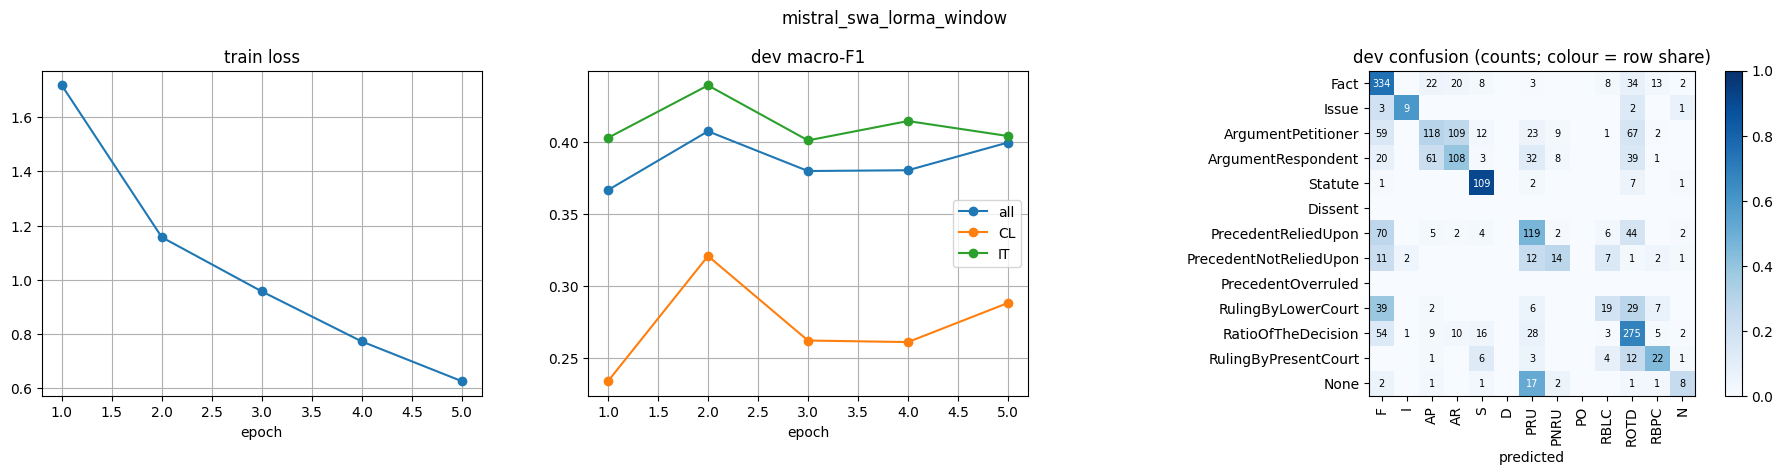

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

{
 "run": "mistral_swa_lorma_window",
 "params_total": 100299277,
 "params_trainable": 206605,
 "params_final": 100102669,
 "train_minutes": 3.281213653087616,
 "peak_gpu_gb": 2.03520768,
 "best_epoch": 2,
 "dev": {
  "all": {
   "F1": 0.4072761198463404,
   "P": 0.4346589971657316,
   "R": 0.4047083710909852,
   "n_sentences": 2142
  },
  "CL": {
   "F1": 0.3207913032278321,
   "P": 0.3677201464533409,
   "R": 0.3338671802239264,
   "n_sentences": 1396
  },
  "IT": {
   "F1": 0.43968491434431284,
   "P": 0.4745039157356136,
   "R": 0.429356228456455,
   "n_sentences": 746
  }
 }
}


In [15]:
t0 = time.time(); TRAIN_SCORES = predict_scores(model, TRAIN_IDS); train_predict_seconds = time.time() - t0
score_type = "emissions" if model.crf is not None else "log_probs"
json.dump({d: (s if model.crf is not None else s.clamp(min=1e-8).log()).round(decimals=4).tolist()
           for d, s in TRAIN_SCORES.items()}, open(f"{RUN_DIR}/train_scores.json", "w"))

info = {
    "run": RUN_NAME, "arch": ARCH, "method": METHOD, "context": CONTEXT, "head": HEAD, "sent_lstm": SENT_LSTM,
    "attn": ATTN, "bart_mode": BART_MODE, "p1_repo": P1_REPOS[ARCH], "layers": STUDENT_LAYERS if STUDENT else "all",
    "kept_blocks": model.kept, "labels": LABELS, "train_domains": TRAIN_DOMAINS, "train_ids": TRAIN_IDS,
    "score_type": score_type,
    "config": {k: globals()[k] for k in ("SEED", "MAX_SENT_TOKENS", "WIN_SENTS", "WIN_TOKENS", "STRIDE_TRAIN",
                                         "STRIDE_PRED", "POOL", "EPOCHS", "PATIENCE", "MAX_TRAIN_MINUTES", "BATCH",
                                         "LR", "HEAD_LR", "WEIGHT_DECAY", "WARMUP_FRAC", "GRAD_CLIP", "DROPOUT",
                                         "CLASS_WEIGHTS", "ADAPT_TARGETS", "RANK", "ALPHA", "LORMA_VARIANT",
                                         "IA3_OUT", "IA3_IN", "PROMPT_LEN", "TEACHER_RUN", "STUDENT_LAYERS", "KD_T",
                                         "KD_ALPHA")},
    "params_total": TOTAL_PARAMS, "params_trainable": TRAINABLE_PARAMS, "params_final": n_params(model),
    "train_minutes": train_seconds / 60, "peak_gpu_gb": PEAK_MEM_GB, "best_epoch": best["epoch"],
    "dev_predict_seconds": dev_seconds, "test_predict_seconds": test_seconds,
    "train_predict_seconds": train_predict_seconds,
    "dev": {k: {m: v[m] for m in ("F1", "P", "R", "n_sentences")} for k, v in dev.items()},
    "dev_per_label": dev["all"]["per_label"], "dev_confusion": CM.tolist(), "dev_attainable_F1": oracle["all"]["F1"],
    "teacher": teacher_info and {"run": TEACHER_RUN, "arch": teacher_info["arch"], "method": teacher_info["method"],
                                 "params": teacher_info["params_final"], "dev_F1": teacher_info["dev"]["all"]["F1"],
                                 "dev_predict_seconds": teacher_info["dev_predict_seconds"]},
    "history": history,
}
json.dump(info, open(f"{RUN_DIR}/run_config.json", "w"), indent=1)
if SAVE_WEIGHTS:
    torch.save(model.state_dict(), f"{RUN_DIR}/model.pt")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1, 1, 1.4]})
ep = [h["epoch"] for h in history]
ax[0].plot(ep, [h["train_loss"] for h in history], marker="o"); ax[0].set_title("train loss")
for k in [k for k in history[0] if k.startswith("dev_") and k.endswith("_F1")]:
    ax[1].plot(ep, [h[k] for h in history], marker="o", label=k[4:-3])
ax[1].set_title("dev macro-F1"); ax[1].legend()
for a in ax[:2]: a.set_xlabel("epoch"); a.grid(True)
rown = CM / np.maximum(CM.sum(1, keepdims=True), 1)
im = ax[2].imshow(rown, cmap="Blues", vmin=0, vmax=1)
ax[2].set_xticks(range(C)); ax[2].set_xticklabels(abbr, rotation=90); ax[2].set_yticks(range(C)); ax[2].set_yticklabels(LABELS)
for i in range(C):
    for j in range(C):
        if CM[i, j]: ax[2].text(j, i, int(CM[i, j]), ha="center", va="center", fontsize=7,
                                color="white" if rown[i, j] > 0.5 else "black")
ax[2].set_xlabel("predicted"); ax[2].set_title("dev confusion (counts; colour = row share)")
fig.colorbar(im, ax=ax[2], fraction=0.04)
fig.suptitle(RUN_NAME); plt.tight_layout(); plt.savefig(f"{RUN_DIR}/curves.png", dpi=130); plt.show()

api.create_repo(P3_REPO, private=True, exist_ok=True)
hub_push(lambda: api.upload_folder(folder_path=RUN_DIR, path_in_repo=f"runs/{RUN_NAME}", repo_id=P3_REPO,
                                   commit_message=f"{RUN_NAME} dev F1 {dev['all']['F1']:.4f}"), f"runs/{RUN_NAME}")
try:
    from google.colab import files
    files.download(ZIP)
except Exception:
    pass
print(json.dumps({k: info[k] for k in ("run", "params_total", "params_trainable", "params_final", "train_minutes",
                                       "peak_gpu_gb", "best_epoch", "dev")}, indent=1))

## All Phase-3 runs so far (from `cs781-p3`, every account)
A table of the saved runs and a mechanical count against the §9.2 requirements (which Phase-1 models and which
techniques have runs). Counts only — whether two runs are "substantially different" is your judgement.

In [16]:
REQUIRED_PEFT = {"lora", "rslora", "lorma", "ia3", "prompt"}       # §9.2.1 techniques implemented in this notebook
runs = sorted({f.split("/")[1] for f in api.list_repo_files(P3_REPO) if f.startswith("runs/") and f.endswith("/run_config.json")})
rows = []
for r in runs:
    try:
        rows.append(json.load(open(hf_hub_download(P3_REPO, f"runs/{r}/run_config.json", token=HF_TOKEN, force_download=True))))
    except Exception as e:
        print(f"  !! {r}: {e!r}")
print(f"{'run':40s} {'arch':11s} {'method':7s} {'context':7s} {'head':6s} {'lstm':>4s} {'trainable':>10s} "
      f"{'dev F1':>7s} {'CL':>7s} {'IT':>7s} {'min':>5s}")
for x in rows:
    dv = x["dev"]
    print(f"{x['run'][:40]:40s} {x['arch']:11s} {x['method']:7s} {x['context']:7s} {x['head']:6s} {x['sent_lstm']:4d} "
          f"{x['params_trainable']/1e6:9.3f}M {dv['all']['F1']:7.4f} {dv.get('CL', {}).get('F1', float('nan')):7.4f} "
          f"{dv.get('IT', {}).get('F1', float('nan')):7.4f} {x['train_minutes']:5.1f}")
archs = {x["arch"] for x in rows}; methods = {x["method"] for x in rows}
print(f"\nPhase-1 models with runs: {sorted(archs)}  (missing: {sorted({'llama', 'bart', 'prefixlm', 'mistral_swa'} - archs)})")
print(f"§9.2.1 techniques with runs: {sorted(methods & REQUIRED_PEFT)}  LoRMA: {'lorma' in methods}  KD: {'kd' in methods}")

run_config.json:   0%|          | 0.00/11.2k [00:00<?, ?B/s]

run_config.json:   0%|          | 0.00/10.6k [00:00<?, ?B/s]

run_config.json:   0%|          | 0.00/11.7k [00:00<?, ?B/s]

run                                      arch        method  context head   lstm  trainable  dev F1      CL      IT   min
llama_lorma_window                       llama       lorma   window  linear    0     0.305M  0.4027  0.2911  0.4236   5.3
mistral_swa_lorma_window                 mistral_swa lorma   window  linear    0     0.207M  0.4073  0.3208  0.4397   3.3
prefixlm_lorma_window                    prefixlm    lorma   window  linear    0     0.305M  0.4033  0.3429  0.4083   6.5

Phase-1 models with runs: ['llama', 'mistral_swa', 'prefixlm']  (missing: ['bart'])
§9.2.1 techniques with runs: ['lorma']  LoRMA: True  KD: False
